# 01. 가설 A 검증 — 정상 공정의 변수 관계 (양품 샷 기준)

**출처**: Confluence「사출성형기 공정 및 변수 분석(태인)」 2장 A. 정상 공정의 변수 관계

**목적**: 공정 물리상 "이렇게 움직여야 정상"인 관계(A1~A8)가 실제 양품 데이터에서 성립하는지 확인한다. 성립하는 관계는 **정상 기준선**이 되어, 이후 B 가설(예: B2 흐름 저항 이상형 = 속도-압력 관계에서 벗어난 샷)과 파생변수의 근거가 된다.

| ID | 가설 | 관련 변수 | 예상 방향 |
|---|---|---|---|
| A1 | 사출 속도↑ → 충전 시간↓ | `Max_Injection_Speed`, `Filling_Time` | − |
| A2 | 사출 속도↑ → 사출 압력↑ | `Max_Injection_Speed`, `Max_Injection_Pressure` | + |
| A3 | 속도가 같으면 온도↑ → 압력↓ | 압력 ~ 속도 + 배럴온도 + 금형온도 | 온도 계수 − |
| A4 | 사출 시간은 충전 시간을 포함 | `Injection_Time`, `Filling_Time` | 강한 +, 사출 ≥ 충전 |
| A5 | 스크류 회전↑ → 계량 시간↓, 배압↑ → 계량 시간↑ | `Max_Screw_RPM`, `Average_Back_Pressure`, `Plasticizing_Time` | RPM −, 배압 + |
| A6 | 계량 시간↑ → 사이클 시간↑ | `Plasticizing_Time`, `Cycle_Time` | + |
| A7 | 같은 시스템 센서끼리 같이 움직임 | `Barrel_Temperature_1~6`, `Mold_Temperature_3·4` | 강한 + |
| A8 | 계량량↑ → 쿠션↑ | `Plasticizing_Position`, `Cushion_Position` | + |

**분석 설계** (왜 이렇게 보는지)

1. **양품 샷만** 사용 (`PassOrFail == 0`) — 정상 관계를 불량이 흐리지 않도록
2. **제품별로 따로** — CN7과 RG3는 공정 조건이 완전히 다름 (사출시간 9.5초 vs 1초)
3. **전체 상관 + Run 내 상관을 같이 본다** (가설 C2 대응) — Run마다 운전 조건이 통째로 다르면, 두 변수가 실제로는 무관해도 "Run 평균 차이" 때문에 상관이 생김(또는 가려짐). Run 평균을 빼고 본 **Run 내 상관**이 샷 단위 물리 관계에 더 가까움
4. **판단은 2차에서, 추가 기간은 확인만** (팀 합의) — 2차에서 판정하고, 추가 기간에서도 같은 방향인지 재현 여부를 표시
5. **Spearman 순위상관** 사용 — 이상치·비선형에 강함. 샷이 시간순으로 이어져 있어 p-value는 과대평가되므로 **상관 크기(|ρ|)로 판단**
6. **값 종류가 적은 변수 표시** — 값이 3개 이하면 상관이 거의 계단 모양이라 해석을 조심해야 함

**판정 기준**

| 판정 | 조건 (2차 기준) |
|---|---|
| 지지 | 예상 방향 & 전체·Run 내 모두 \|ρ\| ≥ 0.3 |
| 부분 지지 | 예상 방향이지만 전체·Run 내 중 하나만 \|ρ\| ≥ 0.3 (Run 효과가 섞였거나 가려진 것) |
| 기각 | 반대 방향 & \|ρ\| ≥ 0.3 |
| 판단 보류 | \|ρ\| < 0.3 (관계 약함) 또는 변동이 거의 없는 변수 |

## 1. 설정·데이터

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib import font_manager
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats

BASE_DIR = './base'
OUT_DIR = './outputs/hypA'
os.makedirs(OUT_DIR, exist_ok=True)
PRODUCTS = ['cn7', 'rg3']

STRONG = 0.3        # 판정 기준 |ρ|
LOW_UNIQUE = 3      # 값 종류가 이 이하면 '변동 적음' 표시

_av = {f.name for f in font_manager.fontManager.ttflist}
for _f in ['Malgun Gothic', 'AppleGothic', 'NanumGothic', 'Noto Sans CJK KR', 'Noto Sans CJK JP']:
    if _f in _av:
        mpl.rcParams['font.family'] = _f; break
mpl.rcParams.update({'axes.unicode_minus': False, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e6e5df', 'grid.linewidth': 0.6,
                     'axes.edgecolor': '#b5b4ad', 'axes.labelcolor': '#52514e',
                     'xtick.color': '#6f6e69', 'ytick.color': '#6f6e69'})
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 200)

# 색: Run = 범주형 고정 순서 (순위 아님), 상관 히트맵 = 파랑(−)↔회색(0)↔빨강(+) 발산형
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#4a3aa7', '#e34948']
DIVERGING = LinearSegmentedColormap.from_list('div', ['#184f95', '#6da7ec', '#f0efec', '#ef8a88', '#b52a2a'])
INK, MUTED = '#2b2a27', '#6f6e69'

D = {}
for p in PRODUCTS:
    df = pd.read_csv(os.path.join(BASE_DIR, f'{p}_shots.csv'), parse_dates=['TimeStamp'])
    df = df[(df['split'] != '제외') & (df['PassOrFail'] == 0)].copy()     # 양품 샷만
    D[p] = df
    print(f'[{p}] 양품 샷', df.groupby('split').size().to_dict(), '| Run', df.groupby('split')['run_id'].nunique().to_dict())

[cn7] 양품 샷 {'2차': 592, '추가': 1367} | Run {'2차': 2, '추가': 4}
[rg3] 양품 샷 {'2차': 566, '추가': 29} | Run {'2차': 5, '추가': 1}


## 2. 가설 쌍 정의 + 계산 함수

- 상관은 **raw 값**으로 계산 (Spearman은 순위 기반이라 z/raw 결과 동일. 산점도 단위 해석을 위해 raw 사용)
- **Run 내 상관**: 각 변수에서 Run 평균을 뺀 값끼리의 상관 (Run 간 운전 조건 차이 제거)

In [2]:
PAIRS = [   # (ID, x, y, 예상 부호, 설명)
    ('A1', 'Max_Injection_Speed', 'Filling_Time', -1, '속도↑ → 충전 시간↓'),
    ('A2', 'Max_Injection_Speed', 'Max_Injection_Pressure', +1, '속도↑ → 사출 압력↑'),
    ('A4', 'Filling_Time', 'Injection_Time', +1, '충전 시간 ⊂ 사출 시간'),
    ('A5a', 'Max_Screw_RPM', 'Plasticizing_Time', -1, '스크류 회전↑ → 계량 시간↓'),
    ('A5b', 'Average_Back_Pressure', 'Plasticizing_Time', +1, '배압↑ → 계량 시간↑'),
    ('A6', 'Plasticizing_Time', 'Cycle_Time', +1, '계량 시간↑ → 사이클↑'),
    ('A8', 'Plasticizing_Position', 'Cushion_Position', +1, '계량량↑ → 쿠션↑'),
]
raw = lambda c: f'{c}_raw'

def spearman(x, y):
    ok = x.notna() & y.notna()
    if ok.sum() < 5 or x[ok].nunique() < 2 or y[ok].nunique() < 2:
        return np.nan
    return stats.spearmanr(x[ok], y[ok]).statistic

def within_run(df, col):
    return df[col] - df.groupby('run_id')[col].transform('mean')

def pair_stats(df, x, y):
    X, Y = df[raw(x)], df[raw(y)]
    return {
        'n': len(df),
        'ρ 전체': spearman(X, Y),
        'ρ Run내': spearman(within_run(df, raw(x)), within_run(df, raw(y))),
        'x 값 종류': X.nunique(), 'y 값 종류': Y.nunique(),
    }

def verdict(r_all, r_in, sign, low_var):
    if low_var:
        return '판단 보류(변동 적음)'
    vals = [v for v in (r_all, r_in) if pd.notna(v)]
    if not vals:
        return '판단 보류'
    ok = [np.sign(v) == sign and abs(v) >= STRONG for v in vals]
    bad = [np.sign(v) == -sign and abs(v) >= STRONG for v in vals]
    if all(ok) and len(ok) == 2:
        return '지지'
    if any(ok) and not any(bad):
        return '부분 지지'
    if any(bad) and not any(ok):
        return '기각'
    if any(bad) and any(ok):
        return '판단 보류(전체·Run내 방향 다름)'
    return '판단 보류(관계 약함)'

def replicate(r2, r_add, sign):
    # 추가 기간 재현: 2차 판정 방향과 같은 부호 & |ρ| ≥ STRONG 이면 재현
    if pd.isna(r_add):
        return '-'
    if np.sign(r_add) == sign and abs(r_add) >= STRONG:
        return '재현'
    if np.sign(r_add) == -sign and abs(r_add) >= STRONG:
        return '반대'
    return '약함'

## 3. A1·A2·A4·A5·A6·A8 — 쌍 상관 요약

In [3]:
rows = []
for p in PRODUCTS:
    for hid, x, y, sign, desc in PAIRS:
        rec = {'ID': hid, '제품': p.upper(), '가설': desc, '예상': '+' if sign > 0 else '−'}
        for sp in ['2차', '추가']:
            sub = D[p][D[p]['split'] == sp]
            if len(sub) < 5:
                continue
            s = pair_stats(sub, x, y)
            rec[f'{sp} n'] = s['n']
            rec[f'{sp} ρ전체'] = s['ρ 전체']
            rec[f'{sp} ρRun내'] = s['ρ Run내']
            if sp == '2차':
                low = min(s['x 값 종류'], s['y 값 종류']) <= LOW_UNIQUE
                rec['값 종류(x/y)'] = f"{s['x 값 종류']}/{s['y 값 종류']}"
                rec['판정(2차)'] = verdict(s['ρ 전체'], s['ρ Run내'], sign, low)
        rec['추가 재현'] = replicate(rec.get('2차 ρ전체'), rec.get('추가 ρRun내', rec.get('추가 ρ전체')), sign)
        rows.append(rec)

SUMMARY = pd.DataFrame(rows)
fmt = {c: '{:+.2f}' for c in SUMMARY.columns if 'ρ' in c}
display(SUMMARY.style.format(fmt, na_rep='-'))

,ID,제품,가설,예상,2차 n,2차 ρ전체,2차 ρRun내,값 종류(x/y),판정(2차),추가 n,추가 ρ전체,추가 ρRun내,추가 재현
0,A1,CN7,속도↑ → 충전 시간↓,−,592,-0.96,-0.85,17/13,지지,1367,-0.81,-0.90,재현
1,A2,CN7,속도↑ → 사출 압력↑,+,592,-0.31,-0.58,17/7,기각,1367,-0.84,-0.58,반대
2,A4,CN7,충전 시간 ⊂ 사출 시간,+,592,+0.97,+0.86,13/13,지지,1367,+0.99,+0.94,재현
3,A5a,CN7,스크류 회전↑ → 계량 시간↓,−,592,+0.33,+0.22,8/34,기각,1367,-0.36,+0.04,약함
4,A5b,CN7,배압↑ → 계량 시간↑,+,592,+0.44,-0.38,14/34,판단 보류(전체·Run내 방향 다름),1367,-0.67,-0.34,반대
5,A6,CN7,계량 시간↑ → 사이클↑,+,592,-0.63,-0.33,34/12,기각,1367,-0.16,-0.26,약함
6,A8,CN7,계량량↑ → 쿠션↑,+,592,-0.30,+0.12,13/4,기각,1367,+0.19,+0.05,약함
7,A1,RG3,속도↑ → 충전 시간↓,−,566,-0.78,-0.63,7/2,판단 보류(변동 적음),29,-0.74,-0.74,재현
8,A2,RG3,속도↑ → 사출 압력↑,+,566,-0.82,-0.72,7/10,기각,29,-0.93,-0.93,반대
9,A4,RG3,충전 시간 ⊂ 사출 시간,+,566,+0.12,-0.08,2/3,판단 보류(변동 적음),29,+0.39,+0.39,재현


### 산점도 (2차 양품 샷, 색 = Run)

- 점 하나 = 샷. Run별로 점 구름이 따로 떨어져 있으면 **Run 효과(C2)** 가 큰 것 → 전체 상관과 Run 내 상관이 달라지는 이유
- 제목에 전체 ρ / Run 내 ρ 표시

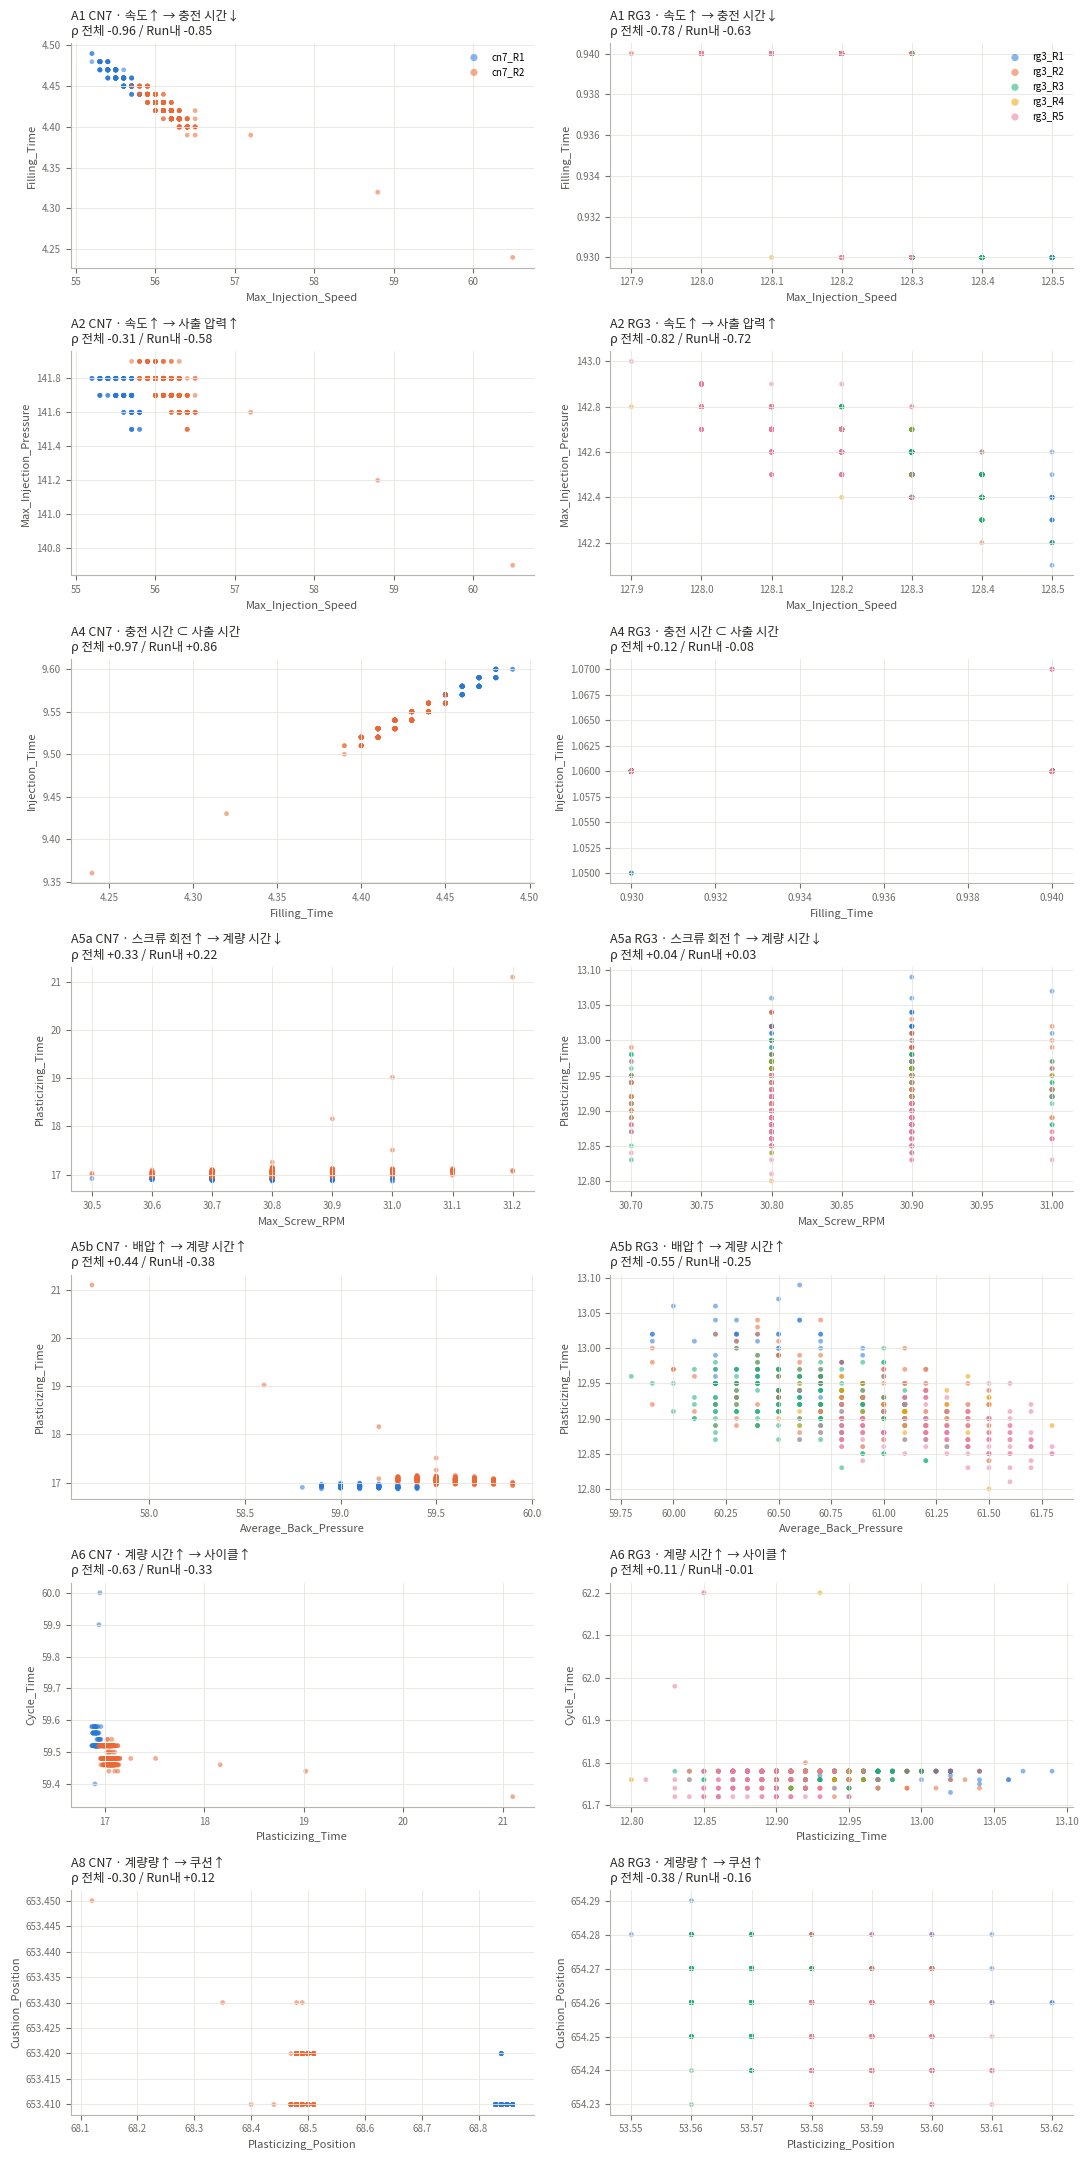

In [4]:
def scatter_grid(split='2차'):
    fig, axes = plt.subplots(len(PAIRS), 2, figsize=(11, 3.1 * len(PAIRS)))
    for j, p in enumerate(PRODUCTS):
        sub = D[p][D[p]['split'] == split]
        runs = list(dict.fromkeys(D[p]['run_id']))                   # 색은 Run에 고정 (전체 기준 순서)
        cmap = {r: SERIES[k % len(SERIES)] for k, r in enumerate(runs)}
        for i, (hid, x, y, sign, desc) in enumerate(PAIRS):
            ax = axes[i, j]
            for r, g in sub.groupby('run_id', sort=False):
                ax.scatter(g[raw(x)], g[raw(y)], s=12, alpha=0.55, color=cmap[r], edgecolors='none', label=r)
            s = pair_stats(sub, x, y)
            ax.set_title(f"{hid} {p.upper()} · {desc}\nρ 전체 {s['ρ 전체']:+.2f} / Run내 {s['ρ Run내']:+.2f}",
                         loc='left', fontsize=9, color=INK)
            ax.set_xlabel(x, fontsize=8); ax.set_ylabel(y, fontsize=8)
            ax.tick_params(labelsize=7)
            ax.ticklabel_format(useOffset=False, style='plain')
            if i == 0:
                ax.legend(fontsize=7, frameon=False, markerscale=1.5, loc='best')
    fig.tight_layout()
    return fig

fig = scatter_grid('2차')
fig.savefig(os.path.join(OUT_DIR, 'pairs_scatter_2차.png'), dpi=130, bbox_inches='tight'); plt.show()

## 4. A4 보충 — 사출 시간 ≥ 충전 시간인가?

상관만으로는 "포함 관계"를 확인할 수 없어서, 모든 샷에서 `Injection_Time ≥ Filling_Time`인지, 차이(= 가압·보압 구간 추정, 파생변수 후보)가 얼마나 일정한지 본다.

In [5]:
rows = []
for p in PRODUCTS:
    for sp in ['2차', '추가']:
        sub = D[p][D[p]['split'] == sp]
        if not len(sub):
            continue
        diff = sub[raw('Injection_Time')] - sub[raw('Filling_Time')]
        rows.append({'제품': p.upper(), 'split': sp, 'n': len(sub),
                     '사출 ≥ 충전 비율': (diff >= 0).mean(),
                     '차이 중앙값(초)': diff.median(), '차이 최소': diff.min(), '차이 최대': diff.max(),
                     '차이 표준편차': diff.std()})
A4 = pd.DataFrame(rows)
display(A4.style.format({'사출 ≥ 충전 비율': '{:.1%}', '차이 중앙값(초)': '{:.2f}', '차이 최소': '{:.2f}',
                          '차이 최대': '{:.2f}', '차이 표준편차': '{:.3f}'}))

,제품,split,n,사출 ≥ 충전 비율,차이 중앙값(초),차이 최소,차이 최대,차이 표준편차
0,CN7,2차,592,100.0%,5.12,5.11,5.12,0.005
1,CN7,추가,1367,100.0%,5.12,5.11,5.12,0.005
2,RG3,2차,566,100.0%,0.12,0.12,0.13,0.005
3,RG3,추가,29,100.0%,0.12,0.12,0.13,0.005


## 5. A3 — 속도가 같을 때 온도↑ → 압력↓ ?

`Max_Injection_Pressure ~ Max_Injection_Speed + 배럴 평균온도 + 금형 평균온도` 를 **표준화 회귀**로 적합해, 속도를 고정했을 때 온도 계수의 부호를 본다.

- 배럴 평균 = `Barrel_Temperature_1~6` 평균, 금형 평균 = `Mold_Temperature_3·4` 평균 (A7에서 센서끼리 같이 움직이는지 확인)
- **Run 고정효과 포함 버전**도 같이 적합 → Run 간 운전 조건 차이를 제거한, Run 안에서의 온도 효과
- 계수 신뢰구간은 **Run 단위 블록 부트스트랩**(Run을 통째로 재추출)은 Run 수가 적어 불안정 → **샷 단위 부트스트랩 500회**로 구하되, 시간 상관 때문에 구간이 실제보다 좁을 수 있음을 감안

In [6]:
BARREL = [f'Barrel_Temperature_{i}' for i in range(1, 7)]
MOLD = ['Mold_Temperature_3', 'Mold_Temperature_4']

def add_temp(df):
    df = df.copy()
    df['Barrel_mean'] = df[[raw(c) for c in BARREL]].mean(axis=1)
    df['Mold_mean'] = df[[raw(c) for c in MOLD]].mean(axis=1)
    df['Speed'] = df[raw('Max_Injection_Speed')]
    df['Pressure'] = df[raw('Max_Injection_Pressure')]
    return df

def std_ols(df, xcols, ycol, run_fe=False):
    d = df[xcols + [ycol, 'run_id']].dropna()
    Z = (d[xcols] - d[xcols].mean()) / d[xcols].std(ddof=0).replace(0, np.nan)
    Z = Z.dropna(axis=1)
    y = (d[ycol] - d[ycol].mean()) / d[ycol].std(ddof=0)
    X = Z.copy()
    if run_fe and d['run_id'].nunique() > 1:
        X = pd.concat([X, pd.get_dummies(d['run_id'], drop_first=True, dtype=float)], axis=1)
    X.insert(0, 'const', 1.0)
    beta, *_ = np.linalg.lstsq(X.values, y.values, rcond=None)
    return pd.Series(beta, index=X.columns)[Z.columns], X, y

rng = np.random.default_rng(0)
XCOLS = ['Speed', 'Barrel_mean', 'Mold_mean']
rows = []
for p in PRODUCTS:
    for sp in ['2차', '추가']:
        sub = add_temp(D[p][D[p]['split'] == sp])
        if len(sub) < 20:
            continue
        for fe in [False, True]:
            if fe and sub['run_id'].nunique() < 2:
                continue
            b, X, y = std_ols(sub, XCOLS, 'Pressure', run_fe=fe)
            boots = []
            for _ in range(500):
                idx = rng.integers(0, len(X), len(X))
                bb, *_ = np.linalg.lstsq(X.values[idx], y.values[idx], rcond=None)
                boots.append(pd.Series(bb, index=X.columns)[b.index])
            boots = pd.DataFrame(boots)
            for c in b.index:
                lo, hi = boots[c].quantile([0.025, 0.975])
                rows.append({'제품': p.upper(), 'split': sp, 'Run 고정효과': 'O' if fe else 'X', '변수': c,
                             '표준화 계수': b[c], '95% 하한': lo, '95% 상한': hi})
A3 = pd.DataFrame(rows)

def a3_verdict(g):
    t = g[g['변수'].isin(['Barrel_mean', 'Mold_mean'])]
    sig_neg = ((t['95% 상한'] < 0)).sum()
    sig_pos = ((t['95% 하한'] > 0)).sum()
    return '지지' if sig_neg and not sig_pos else ('기각' if sig_pos and not sig_neg else '판단 보류')

display(A3.style.format({'표준화 계수': '{:+.2f}', '95% 하한': '{:+.2f}', '95% 상한': '{:+.2f}'}))
A3_V = A3.groupby(['제품', 'split', 'Run 고정효과']).apply(a3_verdict, include_groups=False).rename('A3 판정').reset_index()
display(A3_V)

,제품,split,Run 고정효과,변수,표준화 계수,95% 하한,95% 상한
0,CN7,2차,X,Speed,-0.81,-0.88,-0.69
1,CN7,2차,X,Barrel_mean,-0.12,-0.18,-0.08
2,CN7,2차,X,Mold_mean,-0.68,-0.75,-0.60
3,CN7,2차,O,Speed,-1.01,-1.28,-0.94
4,CN7,2차,O,Barrel_mean,-0.13,-0.18,-0.08
5,CN7,2차,O,Mold_mean,-0.34,-0.42,-0.23
6,CN7,추가,X,Speed,-0.83,-0.95,-0.71
7,CN7,추가,X,Barrel_mean,-0.03,-0.06,-0.00
8,CN7,추가,X,Mold_mean,-0.03,-0.06,-0.00
9,CN7,추가,O,Speed,-0.52,-0.76,-0.44


,제품,split,Run 고정효과,A3 판정
0,CN7,2차,O,지지
1,CN7,2차,X,지지
2,CN7,추가,O,지지
3,CN7,추가,X,지지
4,RG3,2차,O,판단 보류
5,RG3,2차,X,지지
6,RG3,추가,X,판단 보류


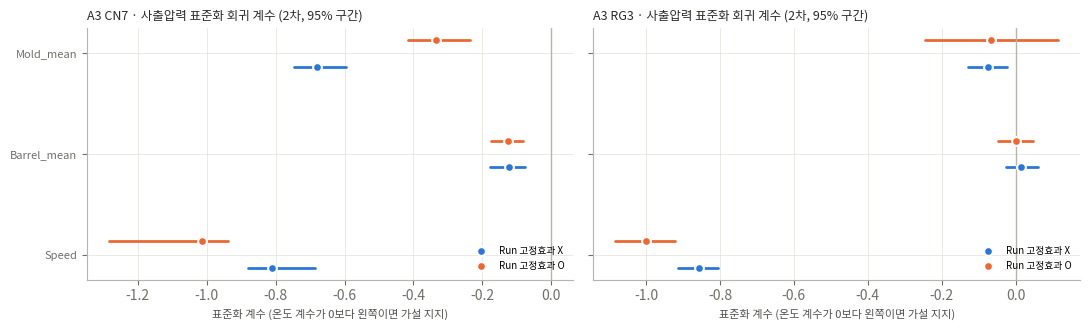

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, p in zip(axes, PRODUCTS):
    t = A3[(A3['제품'] == p.upper()) & (A3['split'] == '2차')]
    labels, ys = [], []
    for k, (fe, g) in enumerate(t.groupby('Run 고정효과', sort=False)):
        for i, (_, r) in enumerate(g.iterrows()):
            y = i * 3 + k * 0.8
            col = SERIES[k]
            ax.plot([r['95% 하한'], r['95% 상한']], [y, y], color=col, lw=2, solid_capstyle='round')
            ax.scatter(r['표준화 계수'], y, s=40, color=col, zorder=3, edgecolors='#fcfcfb', linewidths=1.5,
                       label=f"Run 고정효과 {fe}" if i == 0 else None)
            if k == 0:
                labels.append(r['변수']); ys.append(i * 3 + 0.4)
    ax.axvline(0, color='#b5b4ad', lw=1)
    ax.set_yticks(ys); ax.set_yticklabels(labels, fontsize=8)
    ax.set_title(f'A3 {p.upper()} · 사출압력 표준화 회귀 계수 (2차, 95% 구간)', loc='left', fontsize=9, color=INK)
    ax.set_xlabel('표준화 계수 (온도 계수가 0보다 왼쪽이면 가설 지지)', fontsize=8)
    ax.legend(fontsize=7, frameon=False, loc='lower right')
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, 'A3_coef_2차.png'), dpi=130, bbox_inches='tight'); plt.show()

## 6. A7 — 같은 시스템 센서끼리 같이 움직이는가?

배럴 온도 1~6, 금형 온도 3·4의 Spearman 상관 히트맵 (2차 양품). 전체 / Run 내 두 가지로 본다.
- 전체에서만 높고 Run 내에서 낮으면 → 센서끼리 "같이 흔들리는" 게 아니라 Run마다 설정값이 같이 바뀐 것
- 둘 다 높으면 → 진짜 중복 변수 → 대표 변수 하나로 정리 가능 (회의록 "중복 변수 정리")

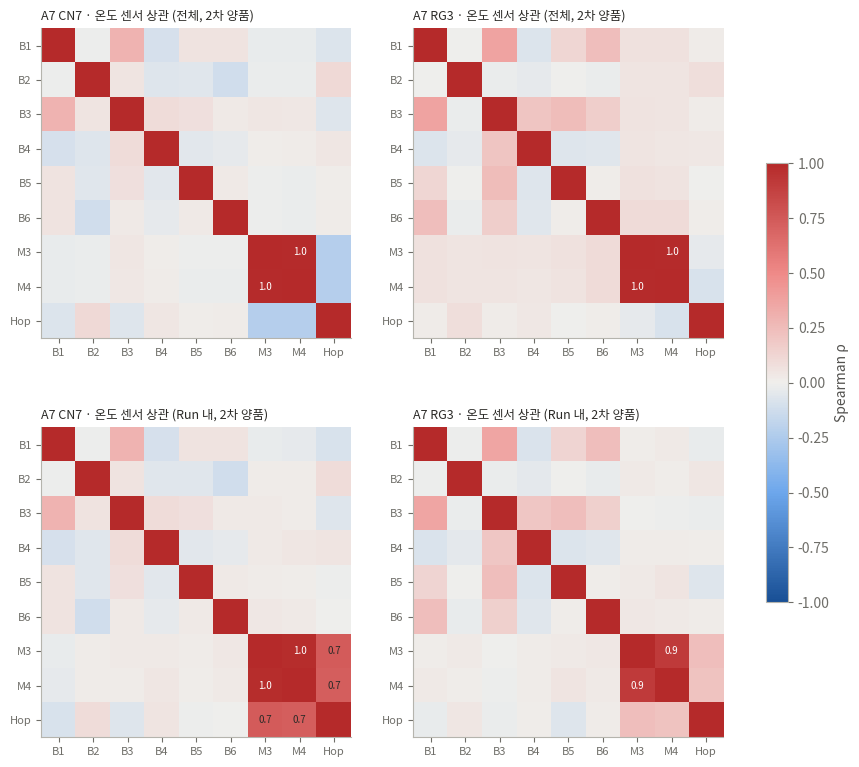

,제품,구분,배럴 1~6 평균 ρ,금형 3·4 ρ,배럴–금형 평균 ρ
0,CN7,전체,+0.02,+0.99,-0.00
1,CN7,Run 내,+0.02,+0.98,+0.02
2,RG3,전체,+0.07,+0.99,+0.06
3,RG3,Run 내,+0.07,+0.91,+0.02


In [8]:
TEMP = BARREL + MOLD + ['Hopper_Temperature']
short = {c: c.replace('Barrel_Temperature_', 'B').replace('Mold_Temperature_', 'M').replace('Hopper_Temperature', 'Hop') for c in TEMP}

def corr_mat(df, within=False):
    X = pd.DataFrame({short[c]: (within_run(df, raw(c)) if within else df[raw(c)]) for c in TEMP})
    X = X.loc[:, X.nunique() > 1]
    return X.corr(method='spearman')

fig, axes = plt.subplots(2, 2, figsize=(11, 9.5))
A7 = {}
for j, p in enumerate(PRODUCTS):
    sub = D[p][D[p]['split'] == '2차']
    for i, within in enumerate([False, True]):
        M = corr_mat(sub, within)
        A7[(p, within)] = M
        ax = axes[i, j]
        im = ax.imshow(M.values, cmap=DIVERGING, vmin=-1, vmax=1)
        ax.set_xticks(range(len(M))); ax.set_xticklabels(M.columns, fontsize=8)
        ax.set_yticks(range(len(M))); ax.set_yticklabels(M.index, fontsize=8)
        ax.grid(False)
        for a in range(len(M)):
            for b in range(len(M)):
                v = M.values[a, b]
                if a != b and abs(v) >= 0.5:
                    ax.text(b, a, f'{v:.1f}', ha='center', va='center', fontsize=7,
                            color='#ffffff' if abs(v) >= 0.75 else INK)
        ax.set_title(f"A7 {p.upper()} · 온도 센서 상관 ({'Run 내' if within else '전체'}, 2차 양품)",
                     loc='left', fontsize=9, color=INK)
fig.colorbar(im, ax=axes, shrink=0.6, label='Spearman ρ')
fig.savefig(os.path.join(OUT_DIR, 'A7_temp_heatmap_2차.png'), dpi=130, bbox_inches='tight'); plt.show()

# 그룹별 요약: 배럴 1~6 끼리, 금형 3·4
def block_mean(M, a, b):
    a = [x for x in a if x in M.index]; b = [x for x in b if x in M.index]
    vals = [M.loc[x, y] for x in a for y in b if x != y]
    return np.nanmean(vals) if vals else np.nan
rows = []
for (p, within), M in A7.items():
    rows.append({'제품': p.upper(), '구분': 'Run 내' if within else '전체',
                 '배럴 1~6 평균 ρ': block_mean(M, [f'B{i}' for i in range(1, 7)], [f'B{i}' for i in range(1, 7)]),
                 '금형 3·4 ρ': M.loc['M3', 'M4'] if {'M3', 'M4'} <= set(M.index) else np.nan,
                 '배럴–금형 평균 ρ': block_mean(M, [f'B{i}' for i in range(1, 7)], ['M3', 'M4'])})
A7_SUM = pd.DataFrame(rows)
display(A7_SUM.style.format({c: '{:+.2f}' for c in A7_SUM.columns if 'ρ' in c}))

## 7. 추가 기간 재현 확인 (산점도)

2차에서 판정한 관계가 학습에 쓰지 않은 추가 기간(CN7 R3~R6, RG3 R6)에서도 보이는지 같은 그림으로 확인한다. RG3 추가 기간은 양품 29샷뿐이라 참고용.

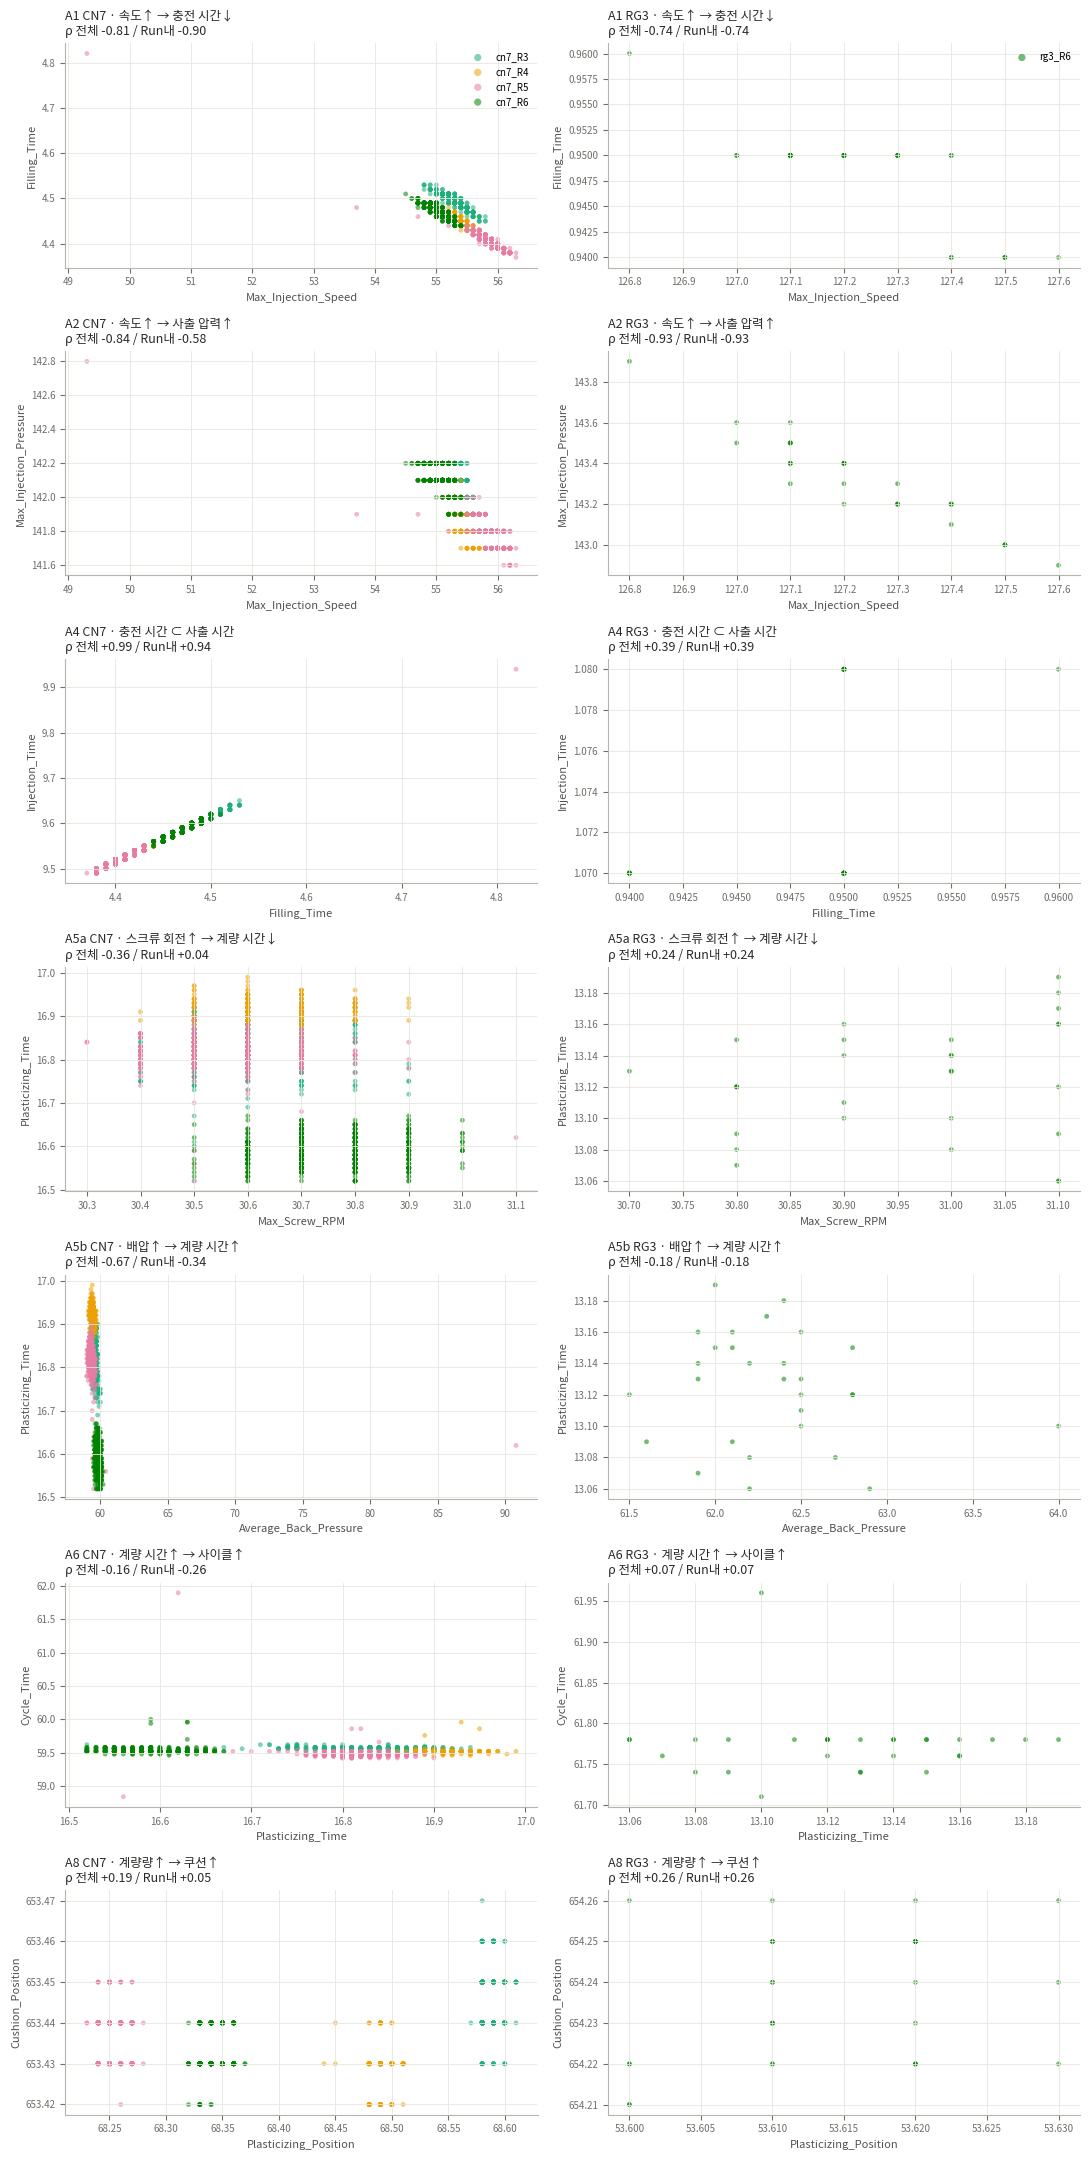

In [9]:
fig = scatter_grid('추가')
fig.savefig(os.path.join(OUT_DIR, 'pairs_scatter_추가.png'), dpi=130, bbox_inches='tight'); plt.show()

## 8. 최종 판정표 + 저장

In [10]:
final = SUMMARY[['ID', '제품', '가설', '예상', '2차 n', '2차 ρ전체', '2차 ρRun내', '값 종류(x/y)', '판정(2차)',
                 '추가 ρ전체', '추가 ρRun내', '추가 재현']].copy()

# A3, A7 행 추가
for p in PRODUCTS:
    v = A3_V[(A3_V['제품'] == p.upper()) & (A3_V['split'] == '2차')].set_index('Run 고정효과')['A3 판정']
    va = A3_V[(A3_V['제품'] == p.upper()) & (A3_V['split'] == '추가')]['A3 판정']
    final = pd.concat([final, pd.DataFrame([{
        'ID': 'A3', '제품': p.upper(), '가설': '속도 고정 시 온도↑ → 압력↓', '예상': '온도 계수 −',
        '판정(2차)': f"전체 {v.get('X', '-')} / Run고정 {v.get('O', '-')}",
        '추가 재현': ', '.join(va) if len(va) else '-'}])], ignore_index=True)
    m_all = A7_SUM[(A7_SUM['제품'] == p.upper()) & (A7_SUM['구분'] == '전체')].iloc[0]
    m_in = A7_SUM[(A7_SUM['제품'] == p.upper()) & (A7_SUM['구분'] == 'Run 내')].iloc[0]
    def a7v(k):
        if m_all[k] >= 0.7 and m_in[k] >= 0.7: return '지지'
        if max(m_all[k], m_in[k]) >= 0.7: return '부분 지지'
        if max(abs(m_all[k]), abs(m_in[k])) < STRONG: return '기각'
        return '판단 보류'
    final = pd.concat([final, pd.DataFrame([{
        'ID': 'A7', '제품': p.upper(), '가설': '같은 시스템 센서끼리 같이 움직임', '예상': '강한 +',
        '2차 ρ전체': m_all['배럴 1~6 평균 ρ'], '2차 ρRun내': m_in['배럴 1~6 평균 ρ'],
        '판정(2차)': f"배럴 {a7v('배럴 1~6 평균 ρ')} / 금형 {a7v('금형 3·4 ρ')} (금형 ρ 전체 {m_all['금형 3·4 ρ']:+.2f}, Run내 {m_in['금형 3·4 ρ']:+.2f})"}])],
        ignore_index=True)

order = {k: i for i, k in enumerate(['A1', 'A2', 'A3', 'A4', 'A5a', 'A5b', 'A6', 'A7', 'A8'])}
final = final.sort_values(['ID', '제품'], key=lambda s: s.map(order) if s.name == 'ID' else s).reset_index(drop=True)
display(final.style.format({c: '{:+.2f}' for c in final.columns if 'ρ' in c}, na_rep='-'))

final.to_csv(os.path.join(OUT_DIR, 'hypA_verdict.csv'), index=False, encoding='utf-8-sig')
SUMMARY.to_csv(os.path.join(OUT_DIR, 'hypA_pairs.csv'), index=False, encoding='utf-8-sig')
A3.to_csv(os.path.join(OUT_DIR, 'hypA_A3_coef.csv'), index=False, encoding='utf-8-sig')
A7_SUM.to_csv(os.path.join(OUT_DIR, 'hypA_A7_temp.csv'), index=False, encoding='utf-8-sig')
print('저장 위치:', os.path.abspath(OUT_DIR))

,ID,제품,가설,예상,2차 n,2차 ρ전체,2차 ρRun내,값 종류(x/y),판정(2차),추가 ρ전체,추가 ρRun내,추가 재현
0,A1,CN7,속도↑ → 충전 시간↓,−,592.000000,-0.96,-0.85,17/13,지지,-0.81,-0.90,재현
1,A1,RG3,속도↑ → 충전 시간↓,−,566.000000,-0.78,-0.63,7/2,판단 보류(변동 적음),-0.74,-0.74,재현
2,A2,CN7,속도↑ → 사출 압력↑,+,592.000000,-0.31,-0.58,17/7,기각,-0.84,-0.58,반대
3,A2,RG3,속도↑ → 사출 압력↑,+,566.000000,-0.82,-0.72,7/10,기각,-0.93,-0.93,반대
4,A3,CN7,속도 고정 시 온도↑ → 압력↓,온도 계수 −,-,-,-,-,전체 지지 / Run고정 지지,-,-,"지지, 지지"
5,A3,RG3,속도 고정 시 온도↑ → 압력↓,온도 계수 −,-,-,-,-,전체 지지 / Run고정 판단 보류,-,-,판단 보류
6,A4,CN7,충전 시간 ⊂ 사출 시간,+,592.000000,+0.97,+0.86,13/13,지지,+0.99,+0.94,재현
7,A4,RG3,충전 시간 ⊂ 사출 시간,+,566.000000,+0.12,-0.08,2/3,판단 보류(변동 적음),+0.39,+0.39,재현
8,A5a,CN7,스크류 회전↑ → 계량 시간↓,−,592.000000,+0.33,+0.22,8/34,기각,-0.36,+0.04,약함
9,A5a,RG3,스크류 회전↑ → 계량 시간↓,−,566.000000,+0.04,+0.03,4/27,판단 보류(관계 약함),+0.24,+0.24,약함


저장 위치: /tmp/claude-0/-home-claude/b6af321b-f66e-5a8f-868b-d67d3934417c/scratchpad/root/KAMP-IMM/notebooks/outputs/hypA


## 해석 가이드 (결과 보고 채우기)

- **지지된 관계** → 정상 기준선. B2(흐름 저항 이상형)처럼 "양품 관계식에서 벗어난 정도(잔차)"를 파생변수로 쓸 수 있음
- **전체 vs Run 내가 다른 관계** → Run 효과(C2)가 섞인 것. B 가설 검증 시 Run 평균 제거 또는 Run 단위 비교 필요
- **기각·판단 보류** → 컬럼 정의가 이름과 다르거나(예: Back_Pressure), 제어 방식 때문에 변동이 없는 변수(예: 시간 계열이 설정값으로 고정). 보고서 1장 "데이터 진단"에 기록
- **값 종류가 적은 변수**(RG3 Filling_Time 2개, Injection_Time 3개 등) → 상관이 계단형이라 판단 보류로 둠

**주의**: Average_Screw_RPM은 전처리에서 제외(스케일 변경)했으므로 A5a는 `Max_Screw_RPM`으로만 확인. Max_Back_Pressure도 제외해서 A5b는 `Average_Back_Pressure`로 확인.